<a href="https://colab.research.google.com/github/jslab-work/boilerplate-rock-paper-scissors/blob/main/Copy_of_fcc_sms_text_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf
import pandas as pd
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

print(tf.__version__)

2.20.0


In [ ]:
# get data files
TRAIN_DATA_URL = "https://raw.githubusercontent.com/beaucarnes/fcc_python_curriculum/master/sms/train-data.tsv"
TEST_DATA_URL = "https://raw.githubusercontent.com/beaucarnes/fcc_python_curriculum/master/sms/valid-data.tsv"

train_file_path = tf.keras.utils.get_file("train-data.tsv", TRAIN_DATA_URL)
test_file_path = tf.keras.utils.get_file("valid-data.tsv", TEST_DATA_URL)

358233/358233 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
118774/118774 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
df_train = pd.read_csv(train_file_path, sep="\t", header=None, names=['y', 'x'])
df_train.head()

,y,x
0,ham,ahhhh...just woken up!had a bad dream about u ...
1,ham,you can never do nothing
2,ham,"now u sound like manky scouse boy steve,like! ..."
3,ham,mum say we wan to go then go... then she can s...
4,ham,never y lei... i v lazy... got wat? dat day ü ...


In [ ]:
df_test = pd.read_csv(test_file_path, sep="\t", header=None, names=['y', 'x'])
df_test.head()

,y,x
0,ham,i am in hospital da. . i will return home in e...
1,ham,"not much, just some textin'. how bout you?"
2,ham,i probably won't eat at all today. i think i'm...
3,ham,don‘t give a flying monkeys wot they think and...
4,ham,who are you seeing?


In [ ]:
print(len(df_train))
print(len(df_test))

4179
1392


In [ ]:
y_train = df_train['y'].astype('category').cat.codes
y_test  = df_test['y'].astype('category').cat.codes
y_train[:5]

,0
0,0
1,0
2,0
3,0
4,0


Text(0.5, 1.0, 'Number of ham and spam messages')

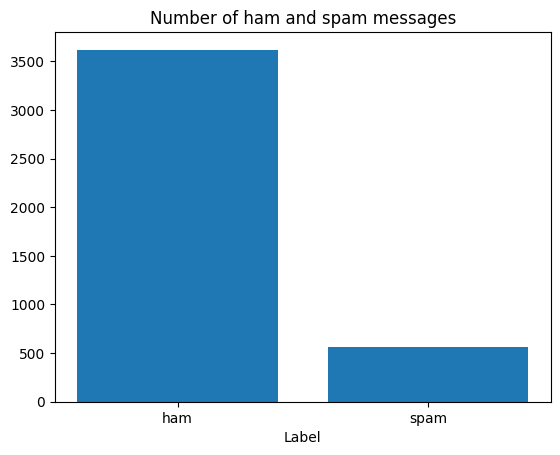

In [ ]:
bar = df_train['y'].value_counts()

plt.bar(bar.index, bar)
plt.xlabel('Label')
plt.title('Number of ham and spam messages')

In [ ]:
import nltk
nltk.download('stopwords') # download stopwords
nltk.download('wordnet')   # download vocab for lemmatizer

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


True

In [ ]:
import re
from nltk.stem import WordNetLemmatizer
from nltk.corpus import stopwords

In [ ]:
stopwords_eng = set(stopwords.words('english'))
len(stopwords_eng)

198

In [ ]:
lemmatizer = WordNetLemmatizer()

def clean_txt(txt):
    txt = re.sub(r'([^\s\w])+', ' ', txt)
    txt = " ".join([lemmatizer.lemmatize(word) for word in txt.split()
                    if not word in stopwords_eng])
    txt = txt.lower()
    return txt

In [ ]:
X_train = df_train['x'].apply(lambda x: clean_txt(x))
X_train[:5]

,x
0,ahhhh woken bad dream u tho dont like u right ...
1,never nothing
2,u sound like manky scouse boy steve like trave...
3,mum say wan go go shun bian watch da glass exh...
4,never lei v lazy got wat dat day ü send da url...


In [ ]:
max_words = 1000   # number of words to keep
max_len = 500      # length of each sequence (must match model input)

In [ ]:
t = Tokenizer(num_words=max_words)
t.fit_on_texts(X_train)

In [ ]:
sequences = t.texts_to_sequences(X_train)
sequences_matrix = pad_sequences(sequences, maxlen=max_len)  # use max_len=500

In [ ]:
i = tf.keras.layers.Input(shape=[max_len])  # shape=[500]
x = tf.keras.layers.Embedding(max_words, 50, input_length=max_len)(i)
x = tf.keras.layers.LSTM(64)(x)
x = tf.keras.layers.Dense(256, activation='relu')(x)
x = tf.keras.layers.Dropout(0.5)(x)
x = tf.keras.layers.Dense(1, activation='sigmoid')(x)  # change from 'relu' to 'sigmoid'

model = tf.keras.models.Model(inputs=i, outputs=x)
model.compile(loss='binary_crossentropy', optimizer='RMSprop', metrics=['accuracy'])


In [ ]:
r = model.fit(sequences_matrix, y_train,
              batch_size=128, epochs=10,
              validation_split=0.2,
              callbacks=[tf.keras.callbacks.EarlyStopping(
                  monitor='val_loss', min_delta=0.0001)])

Epoch 1/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 24s 826ms/step - accuracy: 0.8525 - loss: 0.3687 - val_accuracy: 0.9294 - val_loss: 0.2375
Epoch 2/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 20s 744ms/step - accuracy: 0.9438 - loss: 0.2070 - val_accuracy: 0.9701 - val_loss: 0.1521
Epoch 3/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 21s 791ms/step - accuracy: 0.9722 - loss: 0.1161 - val_accuracy: 0.9701 - val_loss: 0.0903
Epoch 4/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 20s 738ms/step - accuracy: 0.9794 - loss: 0.0712 - val_accuracy: 0.9868 - val_loss: 0.0675
Epoch 5/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 21s 767ms/step - accuracy: 0.9850 - loss: 0.0515 - val_accuracy: 0.9856 - val_loss: 0.0646
Epoch 6/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 39s 730ms/step - accuracy: 0.9892 - loss: 0.0415 - val_accuracy: 0.9856 - val_loss: 0.0591
Epoch 7/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 21s 797ms/step - accuracy: 0.9904 - loss: 0.0362 - val_accuracy: 0.9880 - val_loss: 0.0548
Epoch 8/10
27/27 ━━━━━━━━━━━━━━━━━━━━ 21s 791ms/step - accuracy: 0.9919 - loss: 0.0336 - val_accu

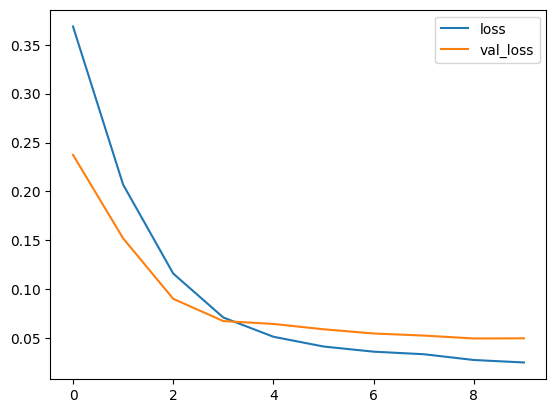

In [ ]:
plt.plot(r.history['loss'], label='loss')
plt.plot(r.history['val_loss'], label='val_loss')
plt.legend()

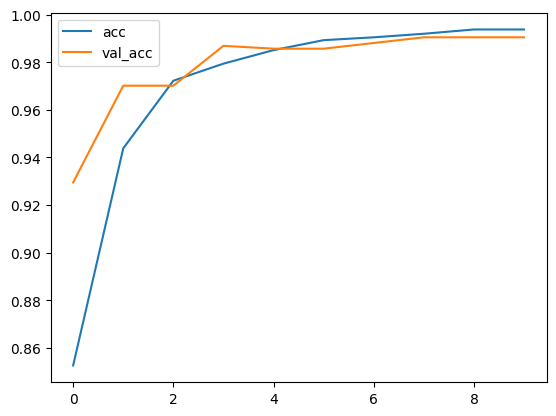

In [ ]:
plt.plot(r.history['accuracy'], label='acc')
plt.plot(r.history['val_accuracy'], label='val_acc')
plt.legend()

In [ ]:
def preprocessing(X):
    x = X.apply(lambda x: clean_txt(x))
    x = t.texts_to_sequences(x)
    return pad_sequences(x, maxlen=max_len)

In [ ]:
s = model.evaluate(preprocessing(df_test['x']), y_test)

44/44 ━━━━━━━━━━━━━━━━━━━━ 4s 85ms/step - accuracy: 0.9871 - loss: 0.0491


In [ ]:
print('Loss: {:.3f}, Accuracy: {:.3f}'.format(s[0], s[1]))

Loss: 0.049, Accuracy: 0.987


In [ ]:
def predict_message(pred_text):
    p = model.predict(preprocessing(pd.Series([pred_text])))[0][0]

    prob = float(p)
    label = "spam" if p >= 0.5 else "ham"

    return [prob, label]

In [ ]:
# Run this cell to test your function and model. Do not modify contents.
def test_predictions():
  test_messages = ["how are you doing today",
                   "sale today! to stop texts call 98912460324",
                   "i dont want to go. can we try it a different day? available sat",
                   "our new mobile video service is live. just install on your phone to start watching.",
                   "you have won £1000 cash! call to claim your prize.",
                   "i'll bring it tomorrow. don't forget the milk.",
                   "wow, is your arm alright. that happened to me one time too"
                  ]

  test_answers = ["ham", "spam", "ham", "spam", "spam", "ham", "ham"]
  passed = True

  for msg, ans in zip(test_messages, test_answers):
    prediction = predict_message(msg)
    if prediction[1] != ans:
      passed = False

  if passed:
    print("You passed the challenge. Great job!")
  else:
    print("You haven't passed yet. Keep trying.")

test_predictions()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 214ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
You passed the challenge. Great job!
